# Problem 2: German Credit Dataset

**Dataset file expected in the same folder:** `GermanCredit.csv`

This notebook follows the assignment order exactly and uses markdown headers before each task. The code also includes a column-normalization step so it can work with common German Credit CSV variants that use slightly different column names.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('default')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

df_raw = pd.read_csv("GermanCredit.csv")
df_raw.head()


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,'<0',6,'critical/other existing credit',radio/tv,1169,'no known savings','>=7',4,'male single',none,4,'real estate',67,none,own,2,skilled,1,yes,yes,good
1,'0<=X<200',48,'existing paid',radio/tv,5951,'<100','1<=X<4',2,'female div/dep/mar',none,2,'real estate',22,none,own,1,skilled,1,none,yes,bad
2,'no checking',12,'critical/other existing credit',education,2096,'<100','4<=X<7',2,'male single',none,3,'real estate',49,none,own,1,'unskilled resident',2,none,yes,good
3,'<0',42,'existing paid',furniture/equipment,7882,'<100','4<=X<7',2,'male single',guarantor,4,'life insurance',45,none,'for free',1,skilled,2,none,yes,good
4,'<0',24,'delayed previously','new car',4870,'<100','1<=X<4',3,'male single',none,4,'no known property',53,none,'for free',2,skilled,2,none,yes,bad


In [2]:

# Normalize column names so the notebook can work with common German Credit CSV variants.

df = df_raw.copy()

rename_map = {
    "status": "checking_status",
    "duration": "duration",
    "credit_history": "credit_history",
    "purpose": "purpose",
    "amount": "credit_amount",
    "credit_amount": "credit_amount",
    "savings": "savings_status",
    "savings_status": "savings_status",
    "employment_duration": "employment",
    "employment": "employment",
    "installment_rate": "installment_commitment",
    "installment_commitment": "installment_commitment",
    "personal_status_sex": "personal_status",
    "personal_status": "personal_status",
    "other_debtors": "other_parties",
    "other_parties": "other_parties",
    "present_residence": "residence_since",
    "residence_since": "residence_since",
    "property": "property_magnitude",
    "property_magnitude": "property_magnitude",
    "other_installment_plans": "other_payment_plans",
    "other_payment_plans": "other_payment_plans",
    "number_credits": "existing_credits",
    "existing_credits": "existing_credits",
    "people_liable": "num_dependents",
    "num_dependents": "num_dependents",
    "telephone": "own_telephone",
    "own_telephone": "own_telephone",
    "credit_risk": "class",
    "class": "class"
}

df = df.rename(columns={col: rename_map.get(col, col) for col in df.columns})

required_columns = [
    "checking_status", "duration", "credit_history", "purpose", "credit_amount",
    "savings_status", "employment", "installment_commitment", "personal_status",
    "other_parties", "residence_since", "property_magnitude", "age",
    "other_payment_plans", "housing", "existing_credits", "job",
    "num_dependents", "own_telephone", "foreign_worker", "class"
]

missing = [c for c in required_columns if c not in df.columns]
print("Missing required columns:", missing)
print("Shape:", df.shape)
df.head()


Missing required columns: []
Shape: (1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,'<0',6,'critical/other existing credit',radio/tv,1169,'no known savings','>=7',4,'male single',none,4,'real estate',67,none,own,2,skilled,1,yes,yes,good
1,'0<=X<200',48,'existing paid',radio/tv,5951,'<100','1<=X<4',2,'female div/dep/mar',none,2,'real estate',22,none,own,1,skilled,1,none,yes,bad
2,'no checking',12,'critical/other existing credit',education,2096,'<100','4<=X<7',2,'male single',none,3,'real estate',49,none,own,1,'unskilled resident',2,none,yes,good
3,'<0',42,'existing paid',furniture/equipment,7882,'<100','4<=X<7',2,'male single',guarantor,4,'life insurance',45,none,'for free',1,skilled,2,none,yes,good
4,'<0',24,'delayed previously','new car',4870,'<100','1<=X<4',3,'male single',none,4,'no known property',53,none,'for free',2,skilled,2,none,yes,bad


## Preprocessing 1
Drop the 3 columns that contribute the least to the dataset. These are the columns with the highest number of non-zero `'none'` values. Break ties from left to right in columns. The helper function should be generalizable for dropping `n` columns, and for the rest of the analysis we use `n=3`.

In [3]:

def drop_most_none_columns(dataframe, n=3):
    none_counts = []
    for idx, col in enumerate(dataframe.columns):
        count = dataframe[col].astype(str).str.strip().str.lower().eq("none").sum()
        none_counts.append((col, count, idx))
    none_counts_sorted = sorted(none_counts, key=lambda x: (-x[1], x[2]))
    cols_to_drop = [col for col, _, _ in none_counts_sorted[:n]]
    return dataframe.drop(columns=cols_to_drop), none_counts_sorted, cols_to_drop

df_step1, none_counts_sorted, cols_dropped = drop_most_none_columns(df, n=3)
print("Columns dropped:", cols_dropped)
print(pd.DataFrame(none_counts_sorted, columns=["column", "none_count", "original_position"]).head(10))

# Safety guard: if a later-required column is dropped because of an unexpected tie in a custom CSV variant,
# reattach it from the original dataframe so the rest of the notebook remains executable.
downstream_needed = [
    "checking_status", "savings_status", "employment", "class", "foreign_worker",
    "credit_amount", "personal_status", "duration", "job", "purpose", "age",
    "property_magnitude", "credit_history"
]
for col in downstream_needed:
    if col not in df_step1.columns and col in df.columns:
        df_step1[col] = df[col]


Columns dropped: ['other_parties', 'other_payment_plans', 'own_telephone']
                column  none_count  original_position
0        other_parties         907                  9
1  other_payment_plans         814                 13
2        own_telephone         596                 18
3      checking_status           0                  0
4             duration           0                  1
5       credit_history           0                  2
6              purpose           0                  3
7        credit_amount           0                  4
8       savings_status           0                  5
9           employment           0                  6


## Preprocessing 2
Certain values in some columns contain unnecessary apostrophes (`'`). Remove the apostrophes.

In [4]:

df_step2 = df_step1.replace({r"'": ""}, regex=True)
df_step2.head()


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,residence_since,property_magnitude,age,housing,existing_credits,job,num_dependents,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,4,real estate,67,own,2,skilled,1,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,2,real estate,22,own,1,skilled,1,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,3,real estate,49,own,1,unskilled resident,2,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,4,life insurance,45,for free,1,skilled,2,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,4,no known property,53,for free,2,skilled,2,yes,bad


## Preprocessing 3
Change `checking_status` values:
- `'no checking'` → `'No Checking'`
- `'<0'` → `'Low'`
- `'0<=X<200'` → `'Medium'`
- `'>=200'` → `'High'`

In [5]:

def normalize_checking_status(value):
    s = str(value).strip().lower().replace(" ", "")
    if "nochecking" in s:
        return "No Checking"
    if s == "<0":
        return "Low"
    if s == "0<=x<200":
        return "Medium"
    if s == ">=200":
        return "High"
    return value

df_step3 = df_step2.copy()
df_step3["checking_status"] = df_step3["checking_status"].apply(normalize_checking_status)
df_step3["checking_status"].value_counts(dropna=False)


checking_status
No Checking    394
Low            274
Medium         269
High            63
Name: count, dtype: int64

## Preprocessing 4
Change `savings_status` values:
- `'no known savings'` → `'No Savings'`
- `'<100'` → `'Low'`
- `'100<=X<500'` → `'Medium'`
- `'500<=X<1000'` → `'High'`
- `'>=1000'` → `'High'`

In [6]:

def normalize_savings_status(value):
    s = str(value).strip().lower().replace(" ", "")
    if "noknownsavings" in s or "unknown/nosavingsaccount" in s:
        return "No Savings"
    if s == "<100" or "...<100dm" in s:
        return "Low"
    if s == "100<=x<500":
        return "Medium"
    if s == "500<=x<1000" or "500<=...<1000dm" in s:
        return "High"
    if s == ">=1000" or "...>=1000dm" in s:
        return "High"
    return value

df_step4 = df_step3.copy()
df_step4["savings_status"] = df_step4["savings_status"].apply(normalize_savings_status)
df_step4["savings_status"].value_counts(dropna=False)


savings_status
Low           603
No Savings    183
High          111
Medium        103
Name: count, dtype: int64

## Preprocessing 5
Change `class` values from `'good'` to `'1'` and `'bad'` to `'0'`.

In [7]:

def normalize_class(value):
    s = str(value).strip().lower()
    if s in {"good", "1"}:
        return "1"
    if s in {"bad", "0", "2"}:
        return "0"
    return str(value)

df_step5 = df_step4.copy()
df_step5["class"] = df_step5["class"].apply(normalize_class)
df_step5["class"].value_counts(dropna=False)


class
1    700
0    300
Name: count, dtype: int64

## Preprocessing 6
Change the `employment` value `'unemployed'` to `'Unemployed'`, and change the remaining employment year ranges to `'Amateur'`, `'Professional'`, `'Experienced'`, and `'Expert'`.

In [8]:

def normalize_employment(value):
    s = str(value).strip().lower().replace(" ", "")
    if "unemployed" in s:
        return "Unemployed"
    if s in {"<1", "...<1year"}:
        return "Amateur"
    if s in {"1<=x<4", "1<=...<4years"}:
        return "Professional"
    if s in {"4<=x<7", "4<=...<7years"}:
        return "Experienced"
    if s in {">=7", "...>=7years"}:
        return "Expert"
    return value

df_clean = df_step5.copy()
df_clean["employment"] = df_clean["employment"].apply(normalize_employment)
df_clean.head()


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,residence_since,property_magnitude,age,housing,existing_credits,job,num_dependents,foreign_worker,class
0,Low,6,critical/other existing credit,radio/tv,1169,No Savings,Expert,4,male single,4,real estate,67,own,2,skilled,1,yes,1
1,Medium,48,existing paid,radio/tv,5951,Low,Professional,2,female div/dep/mar,2,real estate,22,own,1,skilled,1,yes,0
2,No Checking,12,critical/other existing credit,education,2096,Low,Experienced,2,male single,3,real estate,49,own,1,unskilled resident,2,yes,1
3,Low,42,existing paid,furniture/equipment,7882,Low,Experienced,2,male single,4,life insurance,45,for free,1,skilled,2,yes,1
4,Low,24,delayed previously,new car,4870,Low,Professional,3,male single,4,no known property,53,for free,2,skilled,2,yes,0


## Analysis 1a
Get the count of each category of foreign workers (`yes` and `no`) for each class of credit (`good` and `bad` in the original data, now `1` and `0`).

In [9]:

foreign_vs_class = pd.crosstab(df_clean["foreign_worker"], df_clean["class"])
foreign_vs_class


class,0,1
foreign_worker,,
no,4,33
yes,296,667


## Analysis 1b
Get the count of each category of `employment` for each category of `savings_status`.

In [10]:

employment_vs_savings = pd.crosstab(df_clean["employment"], df_clean["savings_status"])
employment_vs_savings


savings_status,High,Low,Medium,No Savings
employment,,,,
Amateur,12,120,17,23
Experienced,18,100,24,32
Expert,34,133,22,64
Professional,44,210,33,52
Unemployed,3,40,7,12


## Analysis 2
Find the average `credit_amount` of single males that have `4<=X<7` years of employment. After preprocessing, this corresponds to `personal_status` containing `male` and `single`, and `employment == 'Experienced'`.

In [11]:

single_male_experienced = df_clean[
    df_clean["personal_status"].astype(str).str.lower().str.contains("male") &
    df_clean["personal_status"].astype(str).str.lower().str.contains("single") &
    (df_clean["employment"] == "Experienced")
]

avg_credit_amount = single_male_experienced["credit_amount"].astype(float).mean()
avg_credit_amount


np.float64(4142.592592592592)

## Analysis 3
Find the average credit duration for each of the job types.

In [12]:

avg_duration_by_job = df_clean.groupby("job")["duration"].mean()
avg_duration_by_job


job
high qualif/self emp/mgmt    25.168919
skilled                      21.411111
unemp/unskilled non res      17.363636
unskilled resident           16.535000
Name: duration, dtype: float64

## Analysis 4
For the purpose `'education'`, print the most common `checking_status` and `savings_status`.

In [13]:

education_df = df_clean[df_clean["purpose"].astype(str).str.lower() == "education"]

most_common_checking = education_df["checking_status"].mode().iloc[0]
most_common_savings = education_df["savings_status"].mode().iloc[0]

print("Most common checking status:", most_common_checking)
print("Most common savings status:", most_common_savings)


Most common checking status: No Checking
Most common savings status: Low


## Visualization 1
Plot subplots of two bar charts: one for `savings_status` (x-axis) to `personal_status` counts, and another for `checking_status` (x-axis) to `personal_status` counts. In each chart, each `personal_status` category should have a different color.

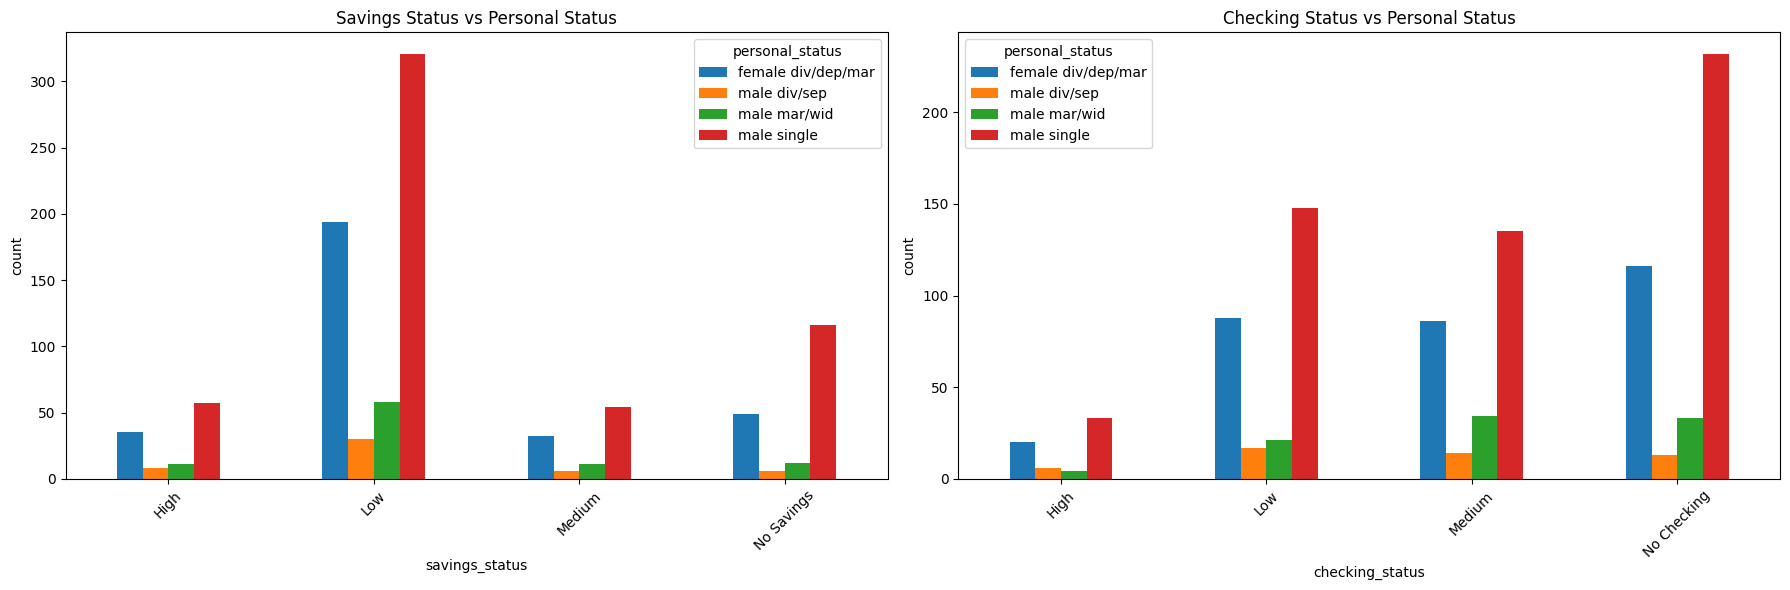

In [14]:

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

pd.crosstab(df_clean["savings_status"], df_clean["personal_status"]).plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Savings Status vs Personal Status")
axes[0].set_xlabel("savings_status")
axes[0].set_ylabel("count")
axes[0].tick_params(axis="x", rotation=45)

pd.crosstab(df_clean["checking_status"], df_clean["personal_status"]).plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Checking Status vs Personal Status")
axes[1].set_xlabel("checking_status")
axes[1].set_ylabel("count")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


## Visualization 2
For people having `credit_amount` more than 4000, plot a bar graph mapping `property_magnitude` (x-axis) to the average customer age for that magnitude (y-axis).

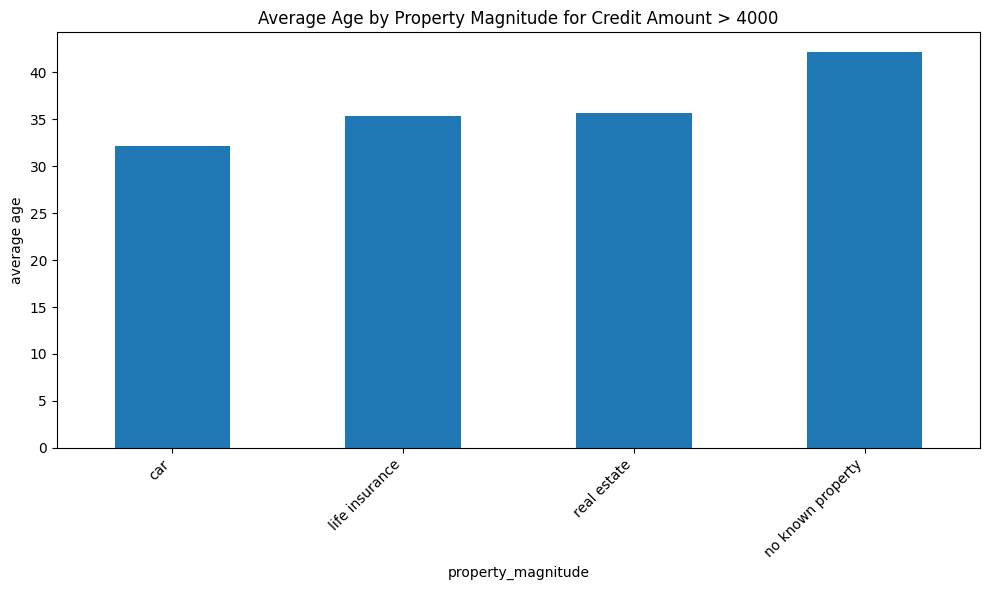

In [15]:

filtered_credit = df_clean[df_clean["credit_amount"].astype(float) > 4000]
avg_age_by_property = filtered_credit.groupby("property_magnitude")["age"].mean().sort_values()

plt.figure(figsize=(10, 6))
avg_age_by_property.plot(kind="bar")
plt.title("Average Age by Property Magnitude for Credit Amount > 4000")
plt.xlabel("property_magnitude")
plt.ylabel("average age")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## Visualization 3
For people with a `'High'` `savings_status` and age above 40, use subplots to plot pie charts for:
1. `personal_status`
2. `credit_history`
3. `job`

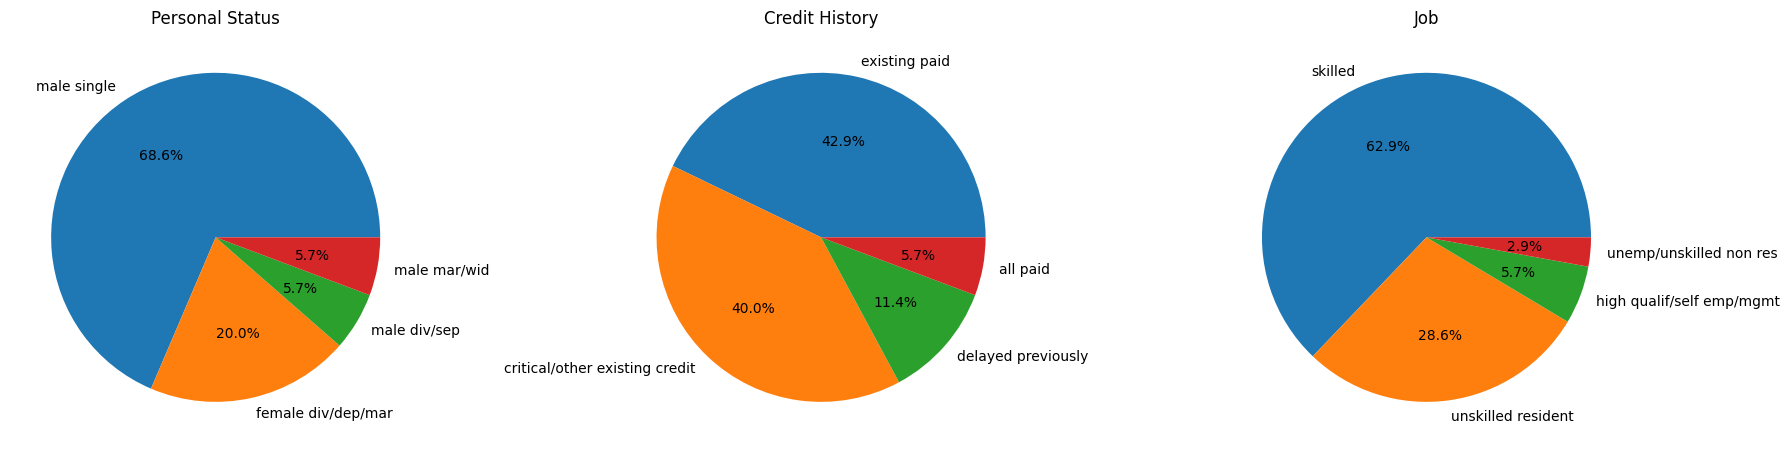

In [16]:

high_savings_40 = df_clean[
    (df_clean["savings_status"] == "High") &
    (df_clean["age"].astype(float) > 40)
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

high_savings_40["personal_status"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[0])
axes[0].set_title("Personal Status")
axes[0].set_ylabel("")

high_savings_40["credit_history"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[1])
axes[1].set_title("Credit History")
axes[1].set_ylabel("")

high_savings_40["job"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[2])
axes[2].set_title("Job")
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()
